# Counterfactual prediction with bi-level quantile regression

*What would this patient's outcome have been on a different dose?* A counterfactual question is about **the same
individual** under another treatment. Answering it takes more than the average effect of the dose: it needs what is
particular about this individual, which we never observe.

This notebook walks through the method of
[Advancing Counterfactual Prediction through Nonlinear Quantile Regression](https://openreview.net/pdf?id=0T1Pd65fyD)
(TMLR 2026) on simulated data, where the true counterfactuals are known:

1. **The idea**: an individual keeps its quantile level under any treatment
2. **Two networks**: one finds the quantile level, the other turns a level into an outcome
3. **Training** them together
4. **Checking** against the truth
5. **When it fails**
6. **Your own networks and data**

Use a GPU runtime (*Runtime → Change runtime type*); each training run then takes a few minutes.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q git+https://github.com/Mid-Push/quantile_counterfactual.git

In [2]:
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from quantile_cf import QuantileCF, ResidualBlock
from quantile_cf.datasets import normal_cdf

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print("device:", device)

device: cuda


## 1. The idea

We simulate a treatment $X$ (say, a dose), a covariate $Z$ (say, age) and an unobserved noise $E$ that makes each
individual different:

$$Y = e^{X - Z + 0.5}\,E, \qquad X, Z \sim U[0, 1], \quad E \sim N(0, 1).$$

The dose amplifies whatever makes an individual different. The median outcome is 0 at every dose, yet a larger dose
raises the outcome of everyone above the median and lowers it for everyone below. So the average effect of the dose
says little about a given individual, and a counterfactual is **not** the observed outcome plus a fixed treatment
effect. We only get to see $(x, z, y)$, never $e$.

In [3]:
def outcome(x, z, e):
    return np.exp(x - z + 0.5) * e

rng = np.random.default_rng(0)
n = 100_000
x = rng.uniform(size=(n, 1))   # treatment
z = rng.uniform(size=(n, 1))   # covariate
e = rng.normal(size=(n, 1))    # unobserved: what makes each individual different
y = outcome(x, z, e)           # observed outcome

Take one individual: $z = 0.5$, treated with $x = 0.2$, with noise $e = 0.8$. Since $Y$ increases with $E$, a larger
noise means a higher position in the distribution of $Y$ given $X$ and $Z$. This individual sits at the quantile level
$\tau = P(Y \le y \mid X = x, Z = z) = \Phi(0.8) \approx 0.79$, and **stays there under every dose**, because the dose
does not change $e$. So its outcome under another dose $x'$ is simply the $\tau$-quantile of $Y$ given $X = x'$ and
$Z = z$:

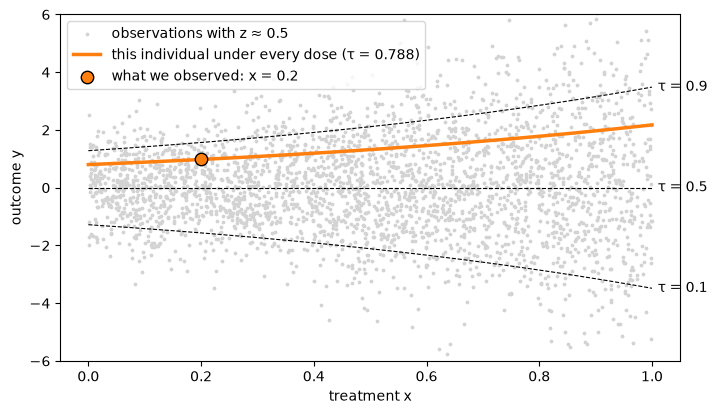

In [4]:
z0, x0, e0 = 0.5, 0.2, 0.8
y0 = outcome(x0, z0, e0)
tau0 = float(normal_cdf(e0))
grid = np.linspace(0, 1, 200)
near = np.flatnonzero(np.abs(z[:, 0] - z0) < 0.05)[:3000]

plt.figure(figsize=(8, 4.5))
plt.scatter(x[near], y[near], s=3, color="lightgray", label="observations with z ≈ 0.5")
for q in (0.1, 0.5, 0.9):
    plt.plot(grid, outcome(grid, z0, NormalDist().inv_cdf(q)), "k--", lw=0.8)
    plt.text(1.01, outcome(1.0, z0, NormalDist().inv_cdf(q)), f"τ = {q}", va="center")
plt.plot(grid, outcome(grid, z0, e0), color="C1", lw=2.5, label=f"this individual under every dose (τ = {tau0:.3f})")
plt.scatter([x0], [y0], color="C1", s=80, zorder=3, edgecolor="k", label="what we observed: x = 0.2")
plt.xlabel("treatment x")
plt.ylabel("outcome y")
plt.ylim(-6, 6)
plt.legend(loc="upper left")
plt.show()

The orange curve answers every counterfactual question about this individual, and it runs along one quantile level.
So two things are enough, and both can be learned from observational data, with no structural equation and no model
of the noise:

* the quantile level $\tau$ of an observation;
* the conditional quantile function: the $\tau$-quantile of $Y$ given $X = x'$ and $Z = z$.

## 2. Two networks

| network | maps | answers |
|---|---|---|
| quantile network | $h(x, z, y) \to \tau \in (0, 1)$ | at which quantile level is $y$, given $x$ and $z$? |
| outcome network | $g(x, z, \tau) \to y$ | what is the $\tau$-quantile of $Y$ given $x$ and $z$? |

The counterfactual outcome under $x'$ is $g(x', z, h(x, z, y))$. Any PyTorch modules with these call signatures can be
used. Here they are written out; the built-in `MLPQuantileNet` and `MLPOutcomeNet` follow the same design.

In [5]:
class QuantileNet(nn.Module):
    """h(x, z, y) -> tau in (0, 1)"""

    def __init__(self, hidden=200):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden), nn.SiLU(),
            ResidualBlock(hidden), ResidualBlock(hidden),
            nn.Linear(hidden, 1), nn.Sigmoid(),
        )

    def forward(self, x, z, y):
        return self.net(torch.cat([z, x, y], dim=1))


class OutcomeNet(nn.Module):
    """g(x, z, tau) -> y"""

    def __init__(self, hidden=200):
        super().__init__()
        self.embed_x = nn.Sequential(nn.Linear(1, hidden), nn.SiLU())
        self.embed_z = nn.Sequential(nn.Linear(1, hidden), nn.SiLU())
        self.embed_tau = nn.Sequential(nn.Linear(1, hidden), nn.SiLU())
        self.head = nn.Sequential(nn.Linear(3 * hidden, hidden), nn.SiLU(), nn.Linear(hidden, 1))

    def forward(self, x, z, tau):
        return self.head(torch.cat([self.embed_z(z), self.embed_x(x), self.embed_tau(tau)], dim=1))

## 3. Training them together

The two networks need each other: $g$ is fitted at the quantile levels that $h$ assigns, and $h$ is judged by how well
$g$ reproduces the observed outcome at that level. This makes a bi-level problem:

* **lower level**: the outcome network minimises the pinball (quantile) loss $\ell_\tau\big(y - g(x, z, \tau)\big)$ on
  a batch of observations, at the quantile levels $\tau = h(\cdot)$ of another batch of observations;
* **upper level**: the quantile network minimises $\big(y - g(x, z, h(x, z, y))\big)^2$, taking into account how $g$
  would adjust when $h$ changes (a hypergradient, approximated with SAMA).

`QuantileCF` alternates `inner_steps=30` outcome-network updates with one quantile-network update. The defaults
follow the paper: Adam with learning rate 0.001, 256 observations at 64 quantile levels in each outcome-network update,
and both learning rates halved every 3000 steps. Use a GPU runtime (*Runtime → Change runtime type*): there this takes
a few minutes, on a CPU much longer.

In [6]:
model = QuantileCF(QuantileNet(), OutcomeNet(), device=device)
model.fit(x, y, z, steps=20_000, log_every=4000)

step   4000  lower (pinball) 0.5203  upper (reconstruction) 0.2752


step   8000  lower (pinball) 0.5072  upper (reconstruction) 0.0514


step  12000  lower (pinball) 0.5067  upper (reconstruction) 0.0369


step  16000  lower (pinball) 0.5065  upper (reconstruction) 0.0224


step  20000  lower (pinball) 0.5067  upper (reconstruction) 0.0221


QuantileCF(quantile_net=QuantileNet, outcome_net=OutcomeNet, step=20000, device=cuda)

## 4. Checking against the truth

First the individual from section 1: its learned quantile level and its predicted outcome under every dose.

quantile level: learned 0.7882, true 0.7881
outcome under every dose: largest error 0.023


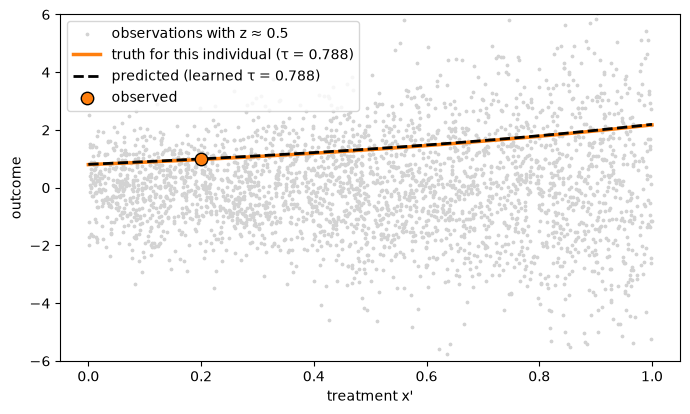

In [7]:
tau0_hat = float(model.quantile([[x0]], [[y0]], [[z0]]))
ones = np.ones((200, 1))
curve = model.counterfactual(x0 * ones, y0 * ones, grid[:, None], z0 * ones).numpy()
print(f"quantile level: learned {tau0_hat:.4f}, true {tau0:.4f}")
print(f"outcome under every dose: largest error {np.abs(curve[:, 0] - outcome(grid, z0, e0)).max():.3f}")

plt.figure(figsize=(8, 4.5))
plt.scatter(x[near], y[near], s=3, color="lightgray", label="observations with z ≈ 0.5")
plt.plot(grid, outcome(grid, z0, e0), color="C1", lw=2.5, label=f"truth for this individual (τ = {tau0:.3f})")
plt.plot(grid, curve, "k--", lw=2, label=f"predicted (learned τ = {tau0_hat:.3f})")
plt.scatter([x0], [y0], color="C1", s=80, zorder=3, edgecolor="k", label="observed")
plt.xlabel("treatment x'")
plt.ylabel("outcome")
plt.ylim(-6, 6)
plt.legend(loc="upper left")
plt.show()

Then 2,000 new individuals, whose true quantile levels $\Phi(e)$ and counterfactual outcomes we know. Each gets a new
random dose $x'$. As a reference, the conditional median $g(x', z, 0.5)$ predicts the same outcome for everyone with
the same $z$.

quantile level, absolute error:  mean 0.004, 90% of individuals below 0.008
counterfactual outcome, RMSE:    0.139
  conditional median instead:    1.985


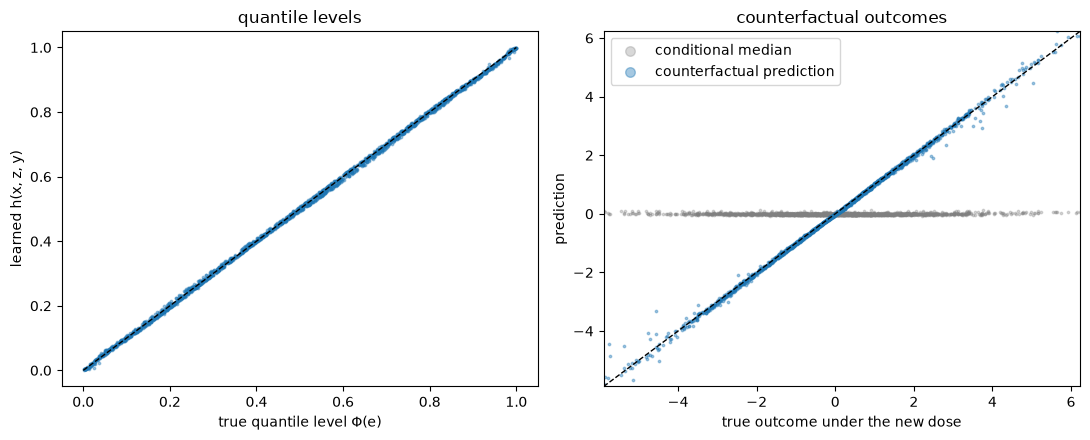

In [8]:
test = np.random.default_rng(1)
m = 2000
x_t, z_t, e_t = test.uniform(size=(m, 1)), test.uniform(size=(m, 1)), test.normal(size=(m, 1))
y_t = outcome(x_t, z_t, e_t)
x_new = test.uniform(size=(m, 1))

tau_hat = model.quantile(x_t, y_t, z_t).numpy()                          # h(x, z, y)
y_cf = model.counterfactual(x_t, y_t, x_new, z_t).numpy()                # g(x', z, h(x, z, y))
y_cf_true = outcome(x_new, z_t, e_t)
y_median = model.predict(x_new, np.full_like(x_new, 0.5), z_t).numpy()  # g(x', z, 0.5)

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

tau_error = np.abs(tau_hat - normal_cdf(e_t))
print(f"quantile level, absolute error:  mean {tau_error.mean():.3f}, 90% of individuals below {np.percentile(tau_error, 90):.3f}")
print(f"counterfactual outcome, RMSE:    {rmse(y_cf, y_cf_true):.3f}")
print(f"  conditional median instead:    {rmse(y_median, y_cf_true):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(normal_cdf(e_t), tau_hat, s=3, alpha=0.4)
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(xlabel="true quantile level Φ(e)", ylabel="learned h(x, z, y)", title="quantile levels")
lim = np.percentile(y_cf_true, [0.5, 99.5])
ax[1].scatter(y_cf_true, y_median, s=3, alpha=0.3, color="gray", label="conditional median")
ax[1].scatter(y_cf_true, y_cf, s=3, alpha=0.4, label="counterfactual prediction")
ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set(xlim=lim, ylim=lim, xlabel="true outcome under the new dose", ylabel="prediction",
          title="counterfactual outcomes")
ax[1].legend(markerscale=4)
plt.tight_layout()
plt.show()

## 5. When it fails

Everything rests on one assumption: the treatment does not change an individual's rank. That holds when $Y$ is
strictly increasing (or decreasing) in some transformation $r(E)$ of the noise, $E$ is independent of $(X, Z)$, and
there is no hidden confounder of $X$ and $Y$. Two weight-loss drugs that work the same way keep patients in the same
order; drugs that work through different mechanisms may not.

Here the noise lowers the outcome when $x < 0.5$ and raises it when $x > 0.5$, so ranks flip:

$$Y = \sin(2\pi X + Z) + (2X - 1)\,E.$$

In [9]:
def flipped(x, z, e):
    return np.sin(2 * np.pi * x + z) + (2 * x - 1) * e

broken = QuantileCF(QuantileNet(), OutcomeNet(), batch_size=128, num_quantiles=32, device=device)
broken.fit(x, flipped(x, z, e), z, steps=3000, log_every=0)

x_t, z_t, e_t = test.uniform(size=(m, 1)), test.uniform(size=(m, 1)), test.normal(size=(m, 1))
x_new = test.uniform(size=(m, 1))
y_cf = broken.counterfactual(x_t, flipped(x_t, z_t, e_t), x_new, z_t).numpy()
y_median = broken.predict(x_new, np.full_like(x_new, 0.5), z_t).numpy()
print(f"counterfactual outcome, RMSE:  {rmse(y_cf, flipped(x_new, z_t, e_t)):.3f}")
print(f"  conditional median instead:  {rmse(y_median, flipped(x_new, z_t, e_t)):.3f}")

counterfactual outcome, RMSE:  0.672
  conditional median instead:  0.574


When ranks flip, keeping the quantile level does worse than ignoring the individual. Check that the assumption is
plausible for your problem before trusting the counterfactuals.

## 6. Your own networks and data

* Any modules work: `quantile_net(x, z, y)` returns `tau` of shape `(n, 1)` in (0, 1), and `outcome_net(x, z, tau)`
  returns something shaped like `y`. Without covariates, both receive `z=None`.
* Ready-made networks for vectors: `MLPQuantileNet` and `MLPOutcomeNet`. For a binary treatment, `num_arms=2` gives
  each arm its own output layers.
* For images there are `ConvQuantileNet` and `ConvOutcomeNet`, or use your own CNNs. For data generated on the fly,
  pass a `torch.utils.data.Dataset` that returns `(x, y, z)`:

  ```python
  from quantile_cf import ConvOutcomeNet, ConvQuantileNet

  model = QuantileCF(ConvQuantileNet(image_size=32), ConvOutcomeNet(image_size=32),
                     lr=2e-3, batch_size=128, num_quantiles=32, query_batch_size=128)
  model.fit(dataset=my_dataset, steps=100_000)
  ```

* `model.save("model.pt")` stores both networks and their optimizers; `model.load("model.pt")` restores them.